# Task 2: Content Type Prediction Model (Movie or TV Show)
**Auspify Technologies – Machine Learning Internship**

Goal: predict whether a Netflix title is a **Movie** or a **TV Show** from its attributes (binary classification).

1. Select relevant features
2. Encode categorical variables
3. Train classification models
4. Evaluate performance
5. Compare model accuracy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RS = 42
df = pd.read_csv("Dataset.csv")
print(df.shape)
df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Exploration: the target variable

type
Movie      0.697
TV Show    0.303
Name: proportion, dtype: float64


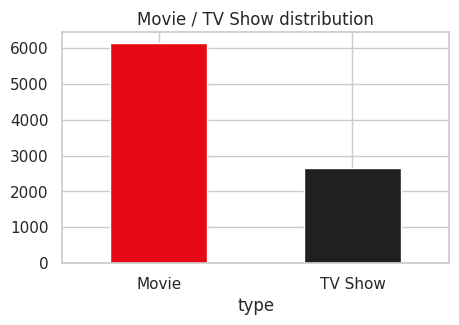

In [2]:
print(df["type"].value_counts(normalize=True).round(3))
df["type"].value_counts().plot.bar(color=["#e50914", "#221f1f"], rot=0, figsize=(5, 3))
plt.title("Movie / TV Show distribution"); plt.show()

The classes are **imbalanced**: about 70% of titles are movies. A model that always answered "Movie" would already reach ~70% accuracy. This score (the **baseline**) is therefore the minimum to beat. We will also track the **F1-score** and the **AUC**, not just accuracy.

## 1. Feature selection, and a data leakage trap

Two columns directly reveal the answer:

In [3]:
# 1) Duration: movies are in minutes, TV shows are in seasons
print(df.groupby("type")["duration"].apply(lambda s: s.str.extract(r"([A-Za-z]+)")[0].value_counts().to_dict()))

# 2) Genres: each genre belongs to a single type
g = df.assign(g=df["listed_in"].str.split(", ")).explode("g").reset_index(drop=True)
tab = pd.crosstab(g["g"], g["type"])
print("\nGenres that are 100% pure:", ((tab["Movie"] == 0) | (tab["TV Show"] == 0)).sum(), "out of", len(tab))
tab.loc[["Dramas", "TV Dramas", "Comedies", "TV Comedies", "International Movies", "International TV Shows"]]

type            
Movie    min        6126.0
         Season        NaN
         Seasons       NaN
TV Show  min           NaN
         Season     1791.0
         Seasons     873.0
Name: duration, dtype: float64

Genres that are 100% pure: 42 out of 42


type,Movie,TV Show
g,,
Dramas,2426,0
TV Dramas,0,762
Comedies,1674,0
TV Comedies,0,573
International Movies,2752,0
International TV Shows,0,1349


- **`duration`**: "90 min" = movie, "2 Seasons" = TV show. Using this column would simply hand the answer to the model.
- **`listed_in`**: genres are named differently depending on the type ("Dramas" for a movie, "TV Dramas" for a TV show). All 42 genres are pure.

The model would get a perfect score in both training and testing, but would have learned nothing useful.SWe call it data leakage.

**Preparing the variables**

In [4]:
data = df.drop_duplicates(subset="title").reset_index(drop=True).copy()
data["target"] = (data["type"] == "TV Show").astype(int)   # 1 = TV Show, 0 = Movie

# Dates
d = pd.to_datetime(data["date_added"], format="%m/%d/%Y", errors="coerce")
data["added_year"]  = d.dt.year.fillna(d.dt.year.median())
data["added_month"] = d.dt.month.fillna(d.dt.month.median())
data["years_to_add"] = data["added_year"] - data["release_year"]   # delay between release and addition to Netflix

# Other simple features
data["director_known"] = (data["director"] != "Not Given").astype(int)
data["n_genres"] = data["listed_in"].str.count(",") + 1
data["country"] = data["country"].fillna("Unknown")

# Duration-related variables (used only in the leakage test)
data["duration_value"] = data["duration"].str.extract(r"(\d+)")[0].astype(float)
data["duration_unit"]  = data["duration"].str.extract(r"([A-Za-z]+)")[0].replace({"Seasons": "Season"})

# Raw genres (multi-hot)
def multi_hot(series, prefix):
    lists = series.str.split(",").apply(lambda xs: [x.strip() for x in xs])
    mh = pd.get_dummies(lists.explode()).groupby(level=0).max().astype(int)
    mh.columns = [f"{prefix}{c}" for c in mh.columns]
    return mh

raw_genres = multi_hot(data["listed_in"], "raw_")

# Normalized genres: remove the words that give away the type (TV, Movies, Shows, Series, Features)
def normalize_genre(x):
    x = re.sub(r"\b(TV|Movies|Shows|Series|Features)\b", "", x)
    return re.sub(r"\s+", " ", x).strip(" &-")

norm = data["listed_in"].str.split(",").apply(
    lambda xs: ",".join(sorted({normalize_genre(x.strip()) for x in xs if normalize_genre(x.strip())})))
norm_genres = multi_hot(norm, "g_")

# Shared genres: only those that exist for both movies AND TV shows
presence = pd.concat([norm_genres, data["type"]], axis=1).groupby("type").sum()
shared_cols = [c for c in norm_genres.columns if (presence[c] > 0).all()]
only_one_type = [c for c in norm_genres.columns if c not in shared_cols]

data = pd.concat([data, raw_genres, norm_genres], axis=1)
print("Raw genres:", raw_genres.shape[1], "| normalized:", norm_genres.shape[1],
      "| shared by both types:", len(shared_cols))
print("Genres specific to a single type:", [c[2:] for c in only_one_type])

Raw genres: 42 | normalized: 32 | shared by both types: 10
Genres specific to a single type: ['British', 'Children & Family', 'Classic', 'Classic & Cult', 'Crime', 'Cult', 'Documentaries', 'Docuseries', 'Faith & Spirituality', 'Independent', "Kids'", 'Korean', 'LGBTQ', 'Music & Musicals', 'Mysteries', 'Reality', 'Science & Nature', 'Spanish-Language', 'Sports', 'Stand-Up Comedy', 'Stand-Up Comedy & Talk', 'Teen']


## 2. Encode categorical variables
- `rating` and `country`: **One-Hot** encoding (rare countries are grouped together).
- Numeric variables: standardized.
- Genres: already in multi-hot format (0/1).

Everything is bundled in a scikit-learn **Pipeline**, so the encoding is learned only from the training data (no leakage).

In [5]:
NUM = ["release_year", "added_year", "added_month", "years_to_add", "n_genres"]
BIN = ["director_known"]
CAT = ["rating", "country"]
RAW = list(raw_genres.columns)
NORM = list(norm_genres.columns)
SHARED = shared_cols

def make_pipeline(model, num, cat, passthrough):
    transformers = [("num", StandardScaler(), num)]
    if cat:
        transformers.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30), cat))
    if passthrough:
        transformers.append(("pass", "passthrough", passthrough))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("model", model)])

y = data["target"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

## 3. Train classification models
The split is **80% train / 20% test**, stratified to keep the class proportions. `class_weight="balanced"` compensates for the imbalance (except for Gradient Boosting).

In [13]:
num, cat, pas = scenarios["D. No duration, shared genres"]
X_train, X_test, y_train, y_test = train_test_split(data, y, test_size=0.2, stratify=y, random_state=RS)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree":       DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RS),
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RS, n_jobs=-1),
    "Gradient Boosting":   HistGradientBoostingClassifier(random_state=RS),
}
fitted = {}
for name, m in models.items():
    fitted[name] = make_pipeline(m, num, cat, pas).fit(X_train, y_train)
print("Training finished:", list(fitted))

Training finished: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


## 4. Evaluate performance
We look at several metrics, with **TV Show as the positive class**:
- **Accuracy**: share of correct predictions
- **Precision**: when the model says "TV show", is it right?
- **Recall**: what share of the real TV shows is found?
- **F1**: which is the trade-off between precision and recall
- **AUC**: ability to separate the two classes (1 = perfect, 0.5 = random)

In [14]:
results = []
for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    cvs = cross_val_score(make_pipeline(models[name], num, cat, pas), data, y, cv=cv, scoring="accuracy")
    results.append({
        "model": name,
        "accuracy (test)": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "AUC": roc_auc_score(y_test, proba),
        "CV accuracy (mean)": cvs.mean(),
        "CV (std dev)": cvs.std(),
    })
res = pd.DataFrame(results).set_index("model").round(3)
print(f"Baseline (always Movie): {1 - y_test.mean():.3f}")
res

Baseline (always Movie): 0.697


,accuracy (test),precision,recall,F1,AUC,CV accuracy (mean),CV (std dev)
model,,,,,,,
Logistic Regression,0.948,0.925,0.901,0.913,0.973,0.952,0.004
Decision Tree,0.948,0.920,0.906,0.913,0.947,0.943,0.007
Random Forest,0.952,0.939,0.899,0.919,0.978,0.953,0.006
Gradient Boosting,0.955,0.938,0.912,0.925,0.980,0.954,0.004


## 5. Compare model accuracy

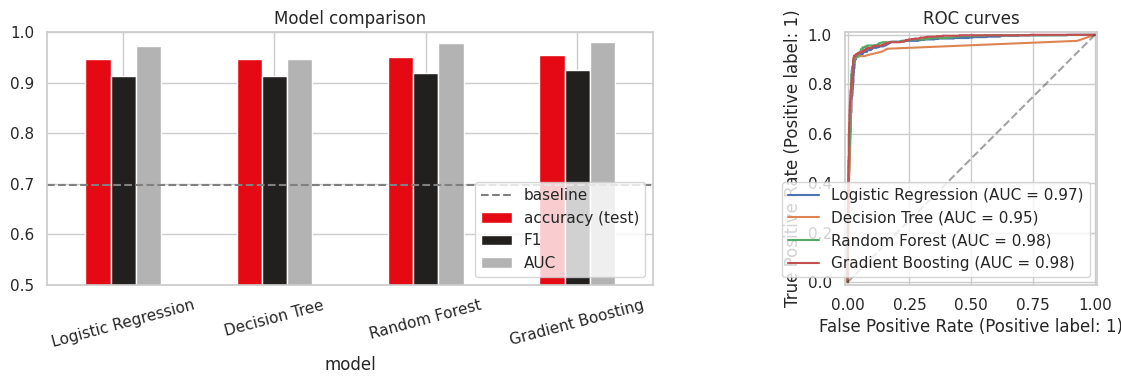

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
res[["accuracy (test)", "F1", "AUC"]].plot.bar(ax=axes[0], rot=15, color=["#e50914", "#221f1f", "#b3b3b3"])
axes[0].axhline(1 - y_test.mean(), color="gray", ls="--", label="baseline")
axes[0].set_ylim(0.5, 1); axes[0].set_title("Model comparison"); axes[0].legend(loc="lower right")

for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4); axes[1].set_title("ROC curves")
plt.tight_layout(); plt.show()

Best model (F1): Gradient Boosting


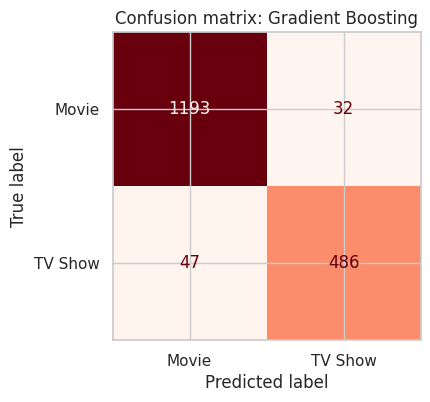

In [16]:
best = res["F1"].idxmax()
print("Best model (F1):", best)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(fitted[best], X_test, y_test, display_labels=["Movie", "TV Show"],
                                      cmap="Reds", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix: {best}"); plt.show()

###  Features importance

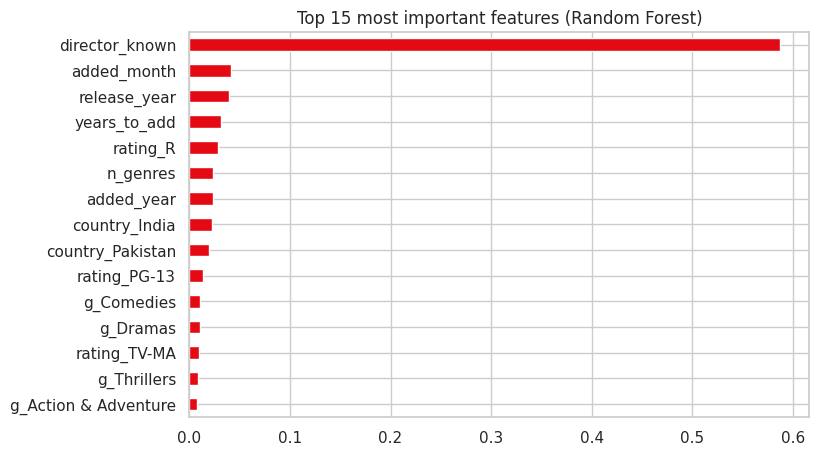

In [17]:
rf = fitted["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False).head(15)
imp.index = [i.split("__", 1)[1] for i in imp.index]
imp.sort_values().plot.barh(figsize=(8, 5), color="#e50914")
plt.title("Top 15 most important features (Random Forest)"); plt.show()

## Conclusion
- **Trap avoided:** duration and the raw genres give almost 100% because they contain the answer (data leakage). Duration was excluded and only the genres shared by both types were kept, in order to get a model that truly predicts.
- With these features, all models clearly beat the ~70% baseline. The table in step 4 shows the best model; the gaps between models are small, which shows that the quality of the features matters more than the choice of algorithm.
- The most informative features are shown in the importance chart above.
- **Limitations:** whether the director is known and the audience rating partly reflect how the dataset was built (movies almost always have a director filled in, TV shows usually do not), and not only properties of the content. The dataset contains neither budget nor synopsis.
- **Next steps:** we suggest to add text features (title, description) with TF-IDF, and tune the hyperparameters with GridSearchCV.